In [ ]:
import cdsapi

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["sea_ice_cover"],
    "year": [
        "1950", "1951", "1952",
        "1953", "1954", "1955",
        "1956", "1957", "1958",
        "1959", "1960", "1961",
        "1962", "1963", "1964",
        "1965", "1966", "1967",
        "1968", "1969", "1970",
        "1971", "1972", "1973",
        "1974", "1975", "1976",
        "1977", "1978", "1979",
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, -180, 50, 180]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

In [ ]:
import cdsapi

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["sea_ice_cover"],
    "year": [
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, -180, 50, 180]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np

In [2]:
ds = xr.load_dataset("ERA5_features/grib_files/sea_ice_50_87.grib", engine="cfgrib")
var_daily1 = ds.siconc.groupby(ds.siconc.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/sea_ice_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
ds = xr.load_dataset("ERA5_features/grib_files/sea_ice_88_25.grib", engine="cfgrib")
var_daily2 = ds.siconc.groupby(ds.siconc.time.dt.date).mean()

Ignoring index file 'ERA5_features/grib_files/sea_ice_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [5]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [6]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [7]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [8]:
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [9]:
lat = var_daily.latitude
lon = var_daily.longitude
barents_kara = (lat >= 65) & (lon < 95) & (lat <= 80) & (lon > 15)

In [10]:
weights = np.cos(np.deg2rad(lat))
weights.name = "weights"

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
var_daily_baka = var_daily.where(barents_kara)

var_daily_bakamean = var_daily_baka.weighted(weights).mean(dim=['longitude', 'latitude'])

In [13]:
var_seasonmean_bakamean = var_daily_bakamean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')

In [14]:
fit_par = np.polyfit(var_seasonmean_bakamean.year[:60], var_seasonmean_bakamean[:60], 1)
var_seasonmean_bakamean_gws_lin = np.polyval(fit_par, var_seasonmean_bakamean.year)

np.float64(0.6031027271890401)

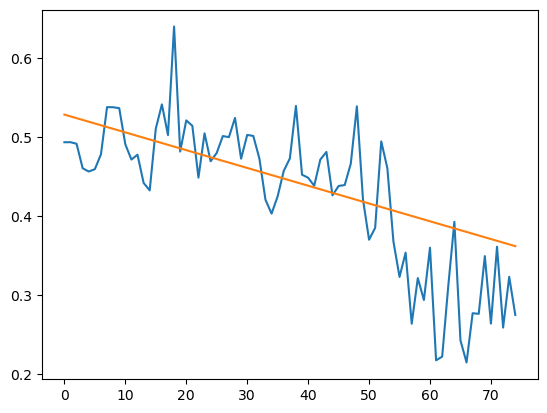

In [15]:
plt.plot(var_seasonmean_bakamean.year, var_seasonmean_bakamean)
plt.plot(var_seasonmean_bakamean.year, var_seasonmean_bakamean_gws_lin)
np.corrcoef(var_seasonmean_bakamean[:60], var_seasonmean_bakamean_gws_lin[:60])[0,1]

<Axes: >

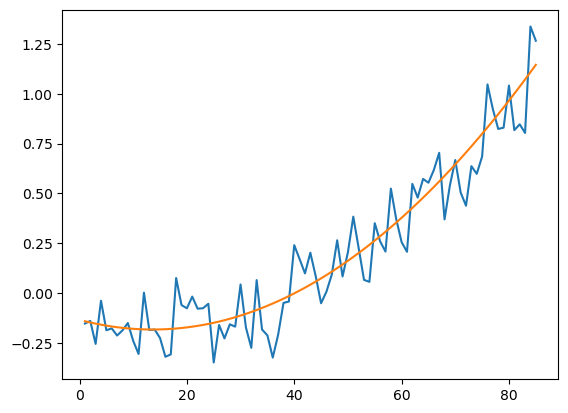

In [16]:
df_gmst = pd.read_csv('era5-0p5deg_world_t2_surface_anom_1951-2000_table.csv', delimiter=',', skiprows=8, usecols=(0,10,11,14))
df_gmst['ONDJF'] = 0.0
df_gmst.loc[1:, 'ONDJF'] = 90/151*df_gmst['DJF'][1:].values + 31/151*df_gmst['Oct'][:-1].values + 30/151*df_gmst['Nov'][:-1].values
df_gmst = df_gmst.drop(index=0)
fit_par = np.polyfit(df_gmst[:70]['Year'], df_gmst[:70]['ONDJF'], 2)
df_gmst['quadr_fit'] = np.polyval(fit_par, df_gmst['Year'])

df_gmst['ONDJF'][:-1].plot()
df_gmst['quadr_fit'][:-1].plot()

In [17]:
fit_par = np.polyfit(df_gmst[10:70]['quadr_fit'], var_seasonmean_bakamean[:60], 1)
var_seasonmean_bakamean_gws = np.polyval(fit_par, df_gmst[10:-1]['quadr_fit'])

np.float64(0.6966310933391382)

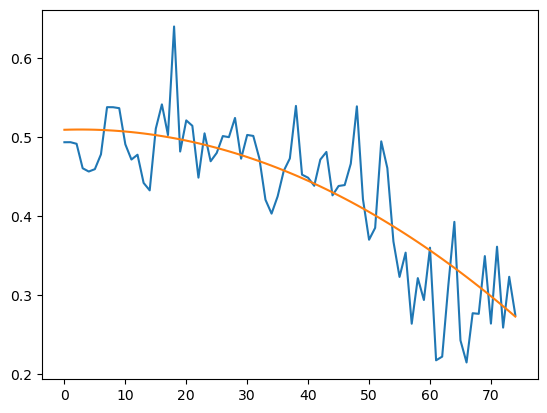

In [18]:
plt.plot(var_seasonmean_bakamean.year, var_seasonmean_bakamean)
plt.plot(var_seasonmean_bakamean.year, var_seasonmean_bakamean_gws)
np.corrcoef(var_seasonmean_bakamean[:60], var_seasonmean_bakamean_gws[:60])[0,1]

In [19]:
var_daily_bakamean_detr = var_daily_bakamean.coarsen(time=151).construct(time=("year", "date")) - var_seasonmean_bakamean_gws[:, np.newaxis]
var_daily_bakamean_detr = var_daily_bakamean_detr.stack(day=("year", "date")).swap_dims({"day": "time"}).reset_coords(('day','year','date'), drop=True)

In [20]:
var_7dMean_bakamean_detr = var_daily_bakamean_detr.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean_bakamean_detr.time.dt.month
day = var_7dMean_bakamean_detr.time.dt.day
var_7dMean_bakamean_detr = var_7dMean_bakamean_detr.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

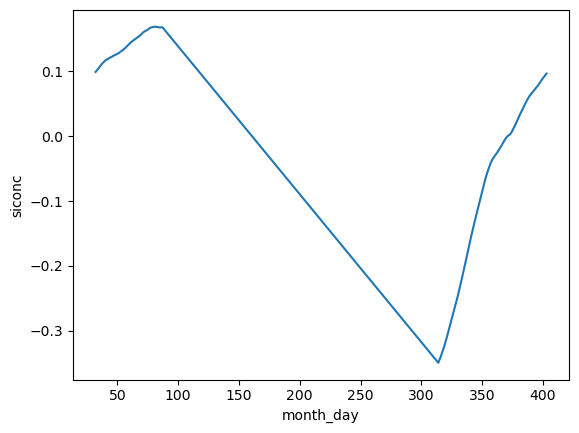

In [21]:
var_7dMean_bakamean_detr_train = var_7dMean_bakamean_detr.sel(time=slice("1950-07", "2010-06"))
var_7dMean_bakamean_detr_train.groupby('month_day').mean().plot()

In [22]:
var_7dMean_bakamean_detr_anom = var_7dMean_bakamean_detr.groupby('month_day') - var_7dMean_bakamean_detr_train.groupby('month_day').mean()

In [23]:
month = var_7dMean_bakamean_detr_anom.time.dt.month
day = var_7dMean_bakamean_detr_anom.time.dt.day
var_7dMean_bakamean_detr_anom_week3 = var_7dMean_bakamean_detr_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_bakamean_detr_anom_week4 = var_7dMean_bakamean_detr_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_bakamean_detr_anom_week5 = var_7dMean_bakamean_detr_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_bakamean_detr_anom_week6 = var_7dMean_bakamean_detr_anom.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_bakamean_detr_anom_week7 = var_7dMean_bakamean_detr_anom.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))

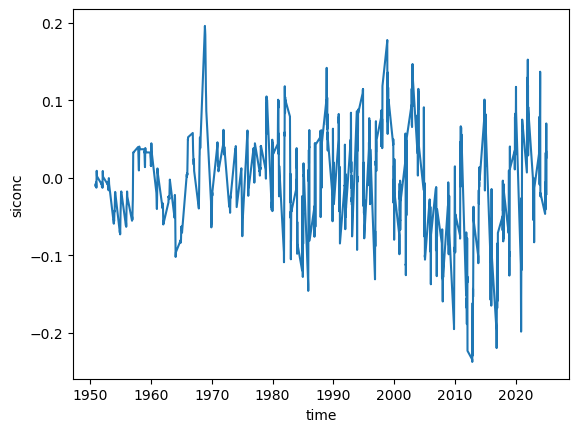

In [24]:
var_7dMean_bakamean_detr_anom_week3.plot()

In [25]:
df_var_week3 = var_7dMean_bakamean_detr_anom_week3.to_dataframe(name='sea_ice_baka')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,sea_ice_baka
time,
1950-11-13,-0.010012
1950-11-14,-0.009106
1950-11-15,-0.008724
1950-11-16,-0.008652
1950-11-17,-0.008769
...,...
2025-01-31,0.004873
2025-02-01,-0.000441
2025-02-02,-0.004828


In [23]:
df_var_week4 = var_7dMean_bakamean_detr_anom_week4.to_dataframe(name='sea_ice_baka')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,sea_ice_baka
time,
1950-11-06,-0.029108
1950-11-07,-0.025259
1950-11-08,-0.021893
1950-11-09,-0.018700
1950-11-10,-0.015880
...,...
2025-01-24,0.067474
2025-01-25,0.060711
2025-01-26,0.052795


In [24]:
df_var_week5 = var_7dMean_bakamean_detr_anom_week5.to_dataframe(name='sea_ice_baka')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,sea_ice_baka
time,
1950-10-30,-0.053788
1950-10-31,-0.052102
1950-11-01,-0.049545
1950-11-02,-0.046290
1950-11-03,-0.042330
...,...
2025-01-17,0.033096
2025-01-18,0.040493
2025-01-19,0.046506


In [25]:
df_var_week6 = var_7dMean_bakamean_detr_anom_week6.to_dataframe(name='sea_ice_baka')
df_var_week6 = df_var_week6.drop(['month_day'], axis=1)
df_var_week6

,sea_ice_baka
time,
1950-10-23,-0.059870
1950-10-24,-0.058497
1950-10-25,-0.057418
1950-10-26,-0.056718
1950-10-27,-0.056181
...,...
2025-01-10,0.034776
2025-01-11,0.034790
2025-01-12,0.033015


In [26]:
df_var_week7 = var_7dMean_bakamean_detr_anom_week7.to_dataframe(name='sea_ice_baka')
df_var_week7 = df_var_week7.drop(['month_day'], axis=1)
df_var_week7

,sea_ice_baka
time,
1950-10-16,-0.063954
1950-10-17,-0.065567
1950-10-18,-0.066065
1950-10-19,-0.065745
1950-10-20,-0.064554
...,...
2025-01-03,-0.014977
2025-01-04,-0.011633
2025-01-05,-0.003730


In [26]:
# Name files appropriately:

df_var_week3.to_csv('baka_sea_ice_week3.csv')

In [25]:
df_var_week4.to_csv('baka_sea_ice_week4.csv')
df_var_week5.to_csv('baka_sea_ice_week5.csv')

In [27]:
df_var_week6.to_csv('baka_sea_ice_week6.csv')
df_var_week7.to_csv('baka_sea_ice_week7.csv')